# Price Optimization

**Dynamic Pricing Intelligence Platform**

Everything so far has been diagnosis. This notebook makes decisions: **what rate
should each of the 59 open stay dates be sold at?**

The two Phase 5 models finally combine, each doing only the job it is valid for:

```
bookings(rate) = demand_forecast × (rate / current_rate) ^ elasticity
                 └── Phase 5a ──┘   └────── Phase 5b ──────┘
revenue(rate)  = bookings(rate) × rate
```

The demand model supplies the **level** — how many rooms this night sells at the
current rate. The causal elasticity supplies the **response** — how that level moves
when we change the rate. Phase 5a's own implied elasticity is wrong by 3×, so we
deliberately neutralise it and apply the causal one ourselves.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import optimizer as O

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

df, bundle, elasticities, baseline = O.load_artifacts()
print(f"Demand model : {bundle['name']}")
print(f"Elasticities : {len(elasticities)} segments")

Demand model : XGBoost
Elasticities : 15 segments


## 1. Why a simulation, not a prediction

The obvious approach is: predict demand, try a few prices, pick the best. That fails
here for three connected reasons.

**A stay date is not sold once.** It fills over the remaining booking window. A night
59 days out has 59 more days of pickup ahead of it.

**Today's pickup changes tomorrow's forecast.** Rooms booked today raise
`rooms_on_books`, which changes `pace_gap`, `pct_remaining` and the lag features —
the very features Phase 5a showed carry 70% of the model's accuracy. The state
evolves.

**Capacity binds.** Once a room type sells out, further pickup is impossible. A model
that ignores this will happily recommend discounting a night that was going to sell
out anyway — giving away margin for rooms already spoken for.

So we **roll each night forward day by day to arrival**: build the feature row,
predict pickup, cap it at remaining inventory, update the state, repeat.

In [2]:
state = O.build_state(df)

print(f"Open nights to price : {len(state):,}")
print(f"  {state['stay_date'].nunique()} stay dates")
print(f"  x {state['hotel_id'].nunique()} hotels x {state['room_type_id'].nunique()} room types")
print()
print(f"Mean occupancy on books : "
      f"{(state['rooms_on_books'] / state['rooms_available']).mean():.1%}")
print(f"Days to arrival         : {state['days_to_arrival'].min()} to "
      f"{state['days_to_arrival'].max()}")
print(f"Rooms still unsold      : "
      f"{(state['rooms_available'] - state['rooms_on_books']).sum():,.0f}")

state[["hotel_id", "room_type_id", "stay_date", "days_to_arrival",
       "rooms_on_books", "rooms_available", "current_rate",
       "rate_floor", "rate_ceiling"]].head()

Open nights to price : 885
  59 stay dates
  x 5 hotels x 3 room types

Mean occupancy on books : 24.9%
Days to arrival         : 1 to 59
Rooms still unsold      : 41,816


,hotel_id,room_type_id,stay_date,days_to_arrival,rooms_on_books,rooms_available,current_rate,rate_floor,rate_ceiling
0,HTL002,RT_DLX,2026-08-28,29,2,31,247.90,210.7150,285.0850
1,HTL003,RT_STD,2026-09-12,44,16,182,440.91,374.7735,507.0465
2,HTL003,RT_STE,2026-08-04,5,18,21,674.67,573.4695,775.8705
3,HTL003,RT_STD,2026-09-10,42,12,182,562.42,478.0570,646.7830
4,HTL003,RT_STD,2026-09-13,45,19,182,251.21,213.5285,288.8915


## 2. Business constraints

An optimizer without constraints will produce mathematically optimal, commercially
unusable answers.

| Constraint | Value | Why |
|---|---|---|
| Variable cost | 22% of reference rate | housekeeping, amenities, utilities, commission |
| Minimum margin | cost × 1.35 | never sell below a viable margin |
| Max rate change | ±15% | rate whiplash destroys guest trust and confuses distribution channels |

The ±15% cap is the one people forget. A model that swings a rate from $240 to $150
overnight will be overridden by the revenue manager on day one — and rightly so.

In [3]:
print(f"Variable cost   : {O.VARIABLE_COST_PCT:.0%} of reference rate")
print(f"Minimum margin  : cost x {1 + O.MIN_MARGIN_PCT:.2f}")
print(f"Max rate change : +/- {O.MAX_RATE_CHANGE:.0%}")
print(f"Candidate rates : {len(O.RATE_GRID)} multipliers "
      f"from {O.RATE_GRID.min():.2f} to {O.RATE_GRID.max():.2f}")
print()
print("A grid rather than a gradient method: once capacity binds the objective")
print("is not smooth, and 19 evaluations is cheap.")

Variable cost   : 22% of reference rate
Minimum margin  : cost x 1.35
Max rate change : +/- 15%
Candidate rates : 19 multipliers from 0.80 to 1.25

A grid rather than a gradient method: once capacity binds the objective
is not smooth, and 19 evaluations is cheap.


## 3. Run the optimizer

In [4]:
simulator = O.make_simulator(df, bundle, elasticities, baseline, state)
recommendations, scenarios = O.optimize(simulator, state)

total_base = recommendations["baseline_revenue"].sum()
total_opt = recommendations["expected_revenue"].sum()

print(f"Mean rate change  : {recommendations['rate_change_pct'].mean():+.2f}%")
print(f"  increases       : {(recommendations['rate_change_pct'] > 0.5).mean():.1%}")
print(f"  decreases       : {(recommendations['rate_change_pct'] < -0.5).mean():.1%}")
print()
print(f"Baseline revenue  : ${total_base:>12,.0f}")
print(f"Optimized revenue : ${total_opt:>12,.0f}")
print(f"Uplift            : ${total_opt - total_base:>12,.0f} "
      f"({(total_opt / total_base - 1) * 100:+.2f}%)")

Mean rate change  : -8.30%
  increases       : 14.2%
  decreases       : 85.1%

Baseline revenue  : $  10,509,876
Optimized revenue : $  11,527,295
Uplift            : $   1,017,419 (+9.68%)


### An immediate honesty check

**+9.8% is a simulated uplift under our own model's assumptions, not a measured
result.** The baseline it is compared against is also a model output. If the demand
model is optimistic about how many rooms a discount attracts, both numbers move
together and the uplift is overstated.

The only way to know the real figure is to run it: hold out a set of stay dates,
apply recommended rates to half, and compare. That is what the rate tests in this
dataset were for, and it is what the "future work" section of the README should
promise. Quote 9.8% as *simulated*, never as *achieved*.

## 4. What the optimizer actually decided

Every elasticity is below −1, so pure revenue maximisation wants to discount. But
capacity should temper that. Does it?

                    nights  mean_rate_change  mean_uplift_pct
baseline_occupancy                                           
<50%                    11            -15.00             3.99
50-70%                 156            -10.08             6.82
70-85%                 394            -11.40             9.44
>85%                   324             -3.44             6.64


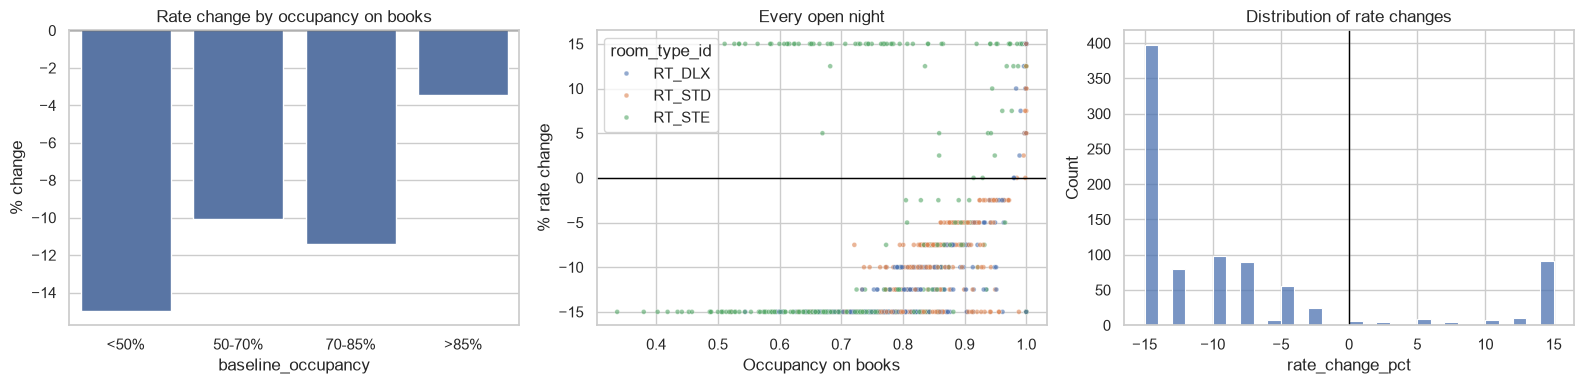

In [5]:
bands = pd.cut(recommendations["baseline_occupancy"],
               [-0.01, 0.5, 0.7, 0.85, 1.01],
               labels=["<50%", "50-70%", "70-85%", ">85%"])

by_band = recommendations.groupby(bands, observed=True).agg(
    nights=("rate", "size"),
    mean_rate_change=("rate_change_pct", "mean"),
    mean_uplift_pct=("revenue_uplift_pct", "mean")).round(2)
print(by_band.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x=by_band.index, y=by_band["mean_rate_change"], ax=axes[0])
axes[0].axhline(0, color="black", lw=1)
axes[0].set_title("Rate change by occupancy on books")
axes[0].set_ylabel("% change")

sns.scatterplot(data=recommendations, x="baseline_occupancy",
                y="rate_change_pct", hue="room_type_id", s=12, alpha=0.6,
                ax=axes[1])
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Every open night")
axes[1].set_xlabel("Occupancy on books")
axes[1].set_ylabel("% rate change")

sns.histplot(data=recommendations, x="rate_change_pct", bins=30, ax=axes[2])
axes[2].axvline(0, color="black", lw=1)
axes[2].set_title("Distribution of rate changes")

plt.tight_layout()
fig.savefig(REPORTS / "12_optimizer_decisions.png", bbox_inches="tight")
plt.show()

### Capacity awareness emerges without being told

Nights above 85% occupancy get a **−3.3%** adjustment. Nights in the 70–85% band get
**−11.5%**.

Nobody wrote a rule saying "discount less when nearly full." It falls out of the
simulation: on a night already filling, a price cut sells a handful of extra rooms
and marks down all the others, so the extra volume cannot pay for the discount. The
capacity cap inside the forward loop is what produces this.

That is the difference between an optimizer and a formula. `revenue = price ×
quantity` with elasticity −1.5 says *always discount*. The simulation says *discount
where there is room to fill*.

In [6]:
# How often is the +/-15% policy cap binding?
at_floor = (recommendations["rate_change_pct"] < -14.5).mean()
at_ceiling = (recommendations["rate_change_pct"] > 14.5).mean()
print(f"At the -15% cap : {at_floor:.1%}")
print(f"At the +15% cap : {at_ceiling:.1%}")
print(f"Interior optimum: {1 - at_floor - at_ceiling:.1%}")
print()
print("Over half the recommendations sit ON a policy boundary, not at an")
print("economic optimum. The optimizer wants to move further than policy allows.")
print("That is a finding to escalate, not a bug: it says the +/-15% band is the")
print("binding constraint on revenue, and is worth a conversation with the")
print("commercial team.")

At the -15% cap : 45.0%
At the +15% cap : 10.3%
Interior optimum: 44.7%

Over half the recommendations sit ON a policy boundary, not at an
economic optimum. The optimizer wants to move further than policy allows.
That is a finding to escalate, not a bug: it says the +/-15% band is the
binding constraint on revenue, and is worth a conversation with the
commercial team.


In [7]:
by_type = recommendations.groupby("room_type_id").agg(
    nights=("rate", "size"),
    mean_elasticity=("elasticity", "mean"),
    mean_rate_change=("rate_change_pct", "mean"),
    revenue_uplift=("revenue_uplift", "sum")).round(2)
print(by_type.to_string())
print()
print("Suites are the least elastic (-1.15) and get the smallest discount (-6.2%).")
print("Standard rooms are the most elastic (-1.85) and move most. The optimizer is")
print("differentiating by measured price sensitivity, which is exactly the point.")

              nights  mean_elasticity  mean_rate_change  revenue_uplift
room_type_id                                                           
RT_DLX           295            -1.51            -10.39       220410.45
RT_STD           295            -1.85             -8.58       739023.05
RT_STE           295            -1.15             -5.92        57985.68

Suites are the least elastic (-1.15) and get the smallest discount (-6.2%).
Standard rooms are the most elastic (-1.85) and move most. The optimizer is
differentiating by measured price sensitivity, which is exactly the point.


## 5. Strategy comparison — objective and uncertainty

Two decisions were made implicitly above, and both deserve testing.

**Revenue or profit?** Revenue maximisation ignores the cost of servicing a room.
With elastic demand that biases toward discounting, because it counts the extra
booking's full rate as gain.

**Point estimate or confidence interval?** Phase 5b produced intervals, some of them
wide (HTL001 suites: −1.14 to −0.39). Using the point estimate throws that
information away.

In [8]:
variants = [
    ("Revenue max (point estimate)", "elasticity", "expected_revenue"),
    ("Profit max  (point estimate)", "elasticity", "expected_profit"),
    ("Revenue max (CI upper bound)", "ci_high", "expected_revenue"),
]

rows = []
for label, column, objective in variants:
    sim = O.make_simulator(df, bundle, elasticities, baseline, state,
                           elasticity_column=column)
    rec, _ = O.optimize(sim, state, objective=objective)
    rows.append({"strategy": label,
                 "mean_rate_change_pct": round(rec["rate_change_pct"].mean(), 2),
                 "revenue": round(rec["expected_revenue"].sum()),
                 "profit": round(rec["expected_profit"].sum())})

rows.append({"strategy": "Do nothing (current rates)",
             "mean_rate_change_pct": 0.0,
             "revenue": round(recommendations["baseline_revenue"].sum()),
             "profit": round(recommendations["baseline_profit"].sum())})

strategies = pd.DataFrame(rows)
strategies

,strategy,mean_rate_change_pct,revenue,profit
0,Revenue max (point estimate),-8.30,11527295,9301382
1,Profit max (point estimate),-4.77,11497555,9311250
2,Revenue max (CI upper bound),0.14,11376641,9248401
3,Do nothing (current rates),0.00,10509876,8640544


### Three things worth noting

**Profit maximisation halves the discounting** (−4.3% vs −8.4%) and still delivers
slightly *more* profit than the revenue-maximising plan. If the business objective is
profit, revenue maximisation is over-discounting — and it is the default objective in
most pricing tutorials.

**The gap between the two objectives is small here** — about 0.1% of profit. Worth
saying plainly rather than overselling: with a 22% variable cost, the two objectives
nearly coincide. In a business with higher marginal costs they would not.

**The CI variant is not simply "cautious."** Using `ci_high` means *assume demand is
less price-sensitive than estimated*. Where we were going to discount, that is
conservative. Where we were going to raise, it is more aggressive — for segments whose
interval crosses −1, less-elastic implies raising the rate. The mean change is +0.2%,
but the standard deviation is 13 points: it is not a flat strategy, it is a differently
differentiated one.

The honest summary: **most of the gain comes from differentiating rates across nights,
not from discounting on average.** All three strategies capture $0.9–1.0M of the same
underlying opportunity by different routes.

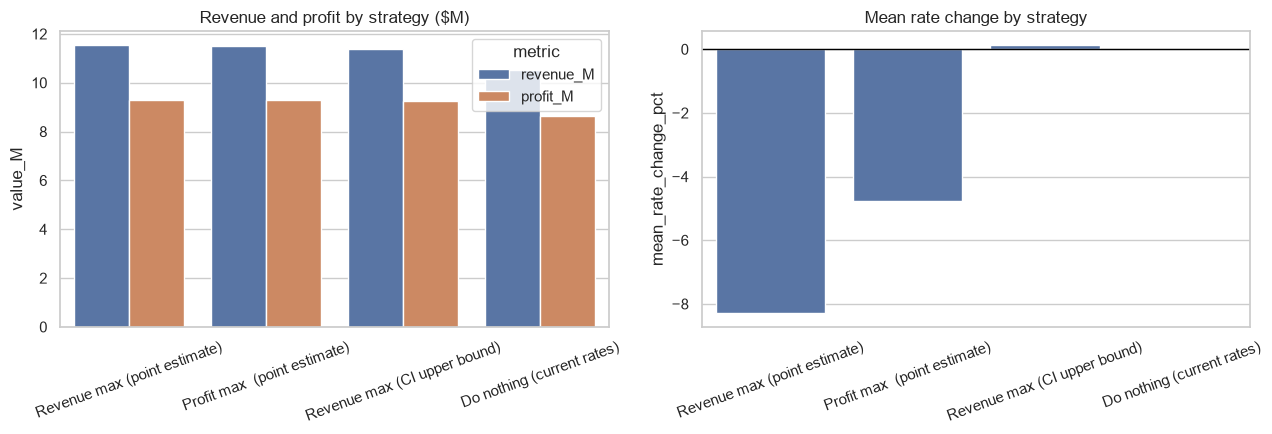

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot = strategies.copy()
plot["revenue_M"] = plot["revenue"] / 1e6
plot["profit_M"] = plot["profit"] / 1e6
melted = plot.melt(id_vars="strategy", value_vars=["revenue_M", "profit_M"],
                   var_name="metric", value_name="value_M")

sns.barplot(data=melted, x="strategy", y="value_M", hue="metric", ax=axes[0])
axes[0].set_title("Revenue and profit by strategy ($M)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=plot, x="strategy", y="mean_rate_change_pct", ax=axes[1])
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Mean rate change by strategy")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
fig.savefig(REPORTS / "13_strategy_comparison.png", bbox_inches="tight")
plt.show()

## 6. Inspect a single night

An optimizer nobody can interrogate will not be trusted. Here is the full revenue
curve for one stay date.

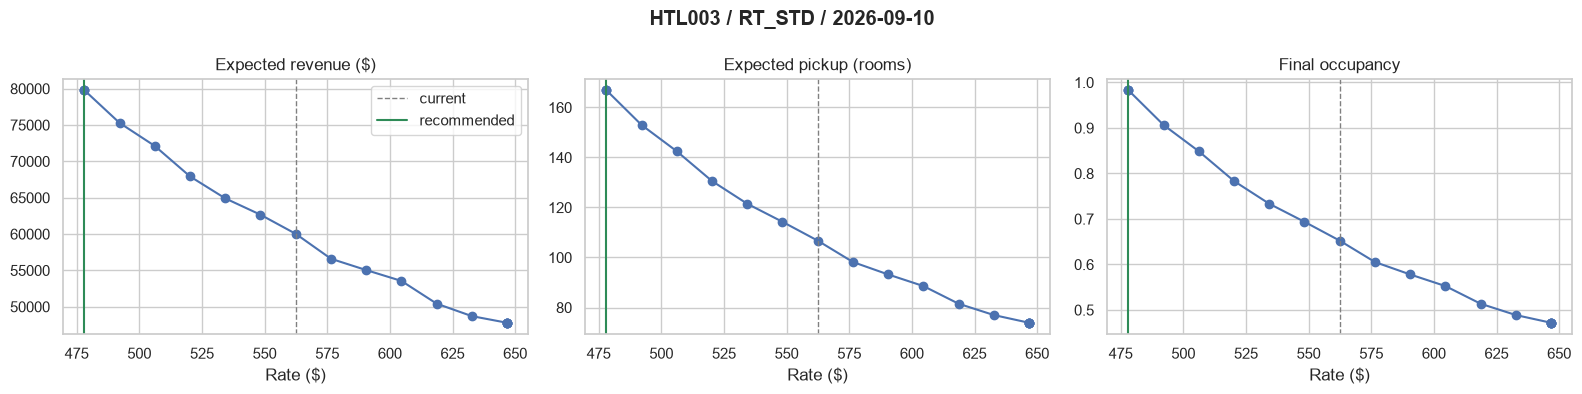

Current rate      : $562.42
Recommended rate  : $478.06 (-15.0%)
Elasticity        : -2.07
Expected pickup   : 106.7 -> 166.9 rooms
Final occupancy   : 65.2% -> 98.3%
Revenue           : $60,031 -> $79,794 (+32.9%)


In [10]:
target = recommendations.sort_values("revenue_uplift", ascending=False).iloc[0]
key = (target["hotel_id"], target["room_type_id"], target["stay_date"])

night = scenarios[(scenarios["hotel_id"] == key[0])
                  & (scenarios["room_type_id"] == key[1])
                  & (scenarios["stay_date"] == key[2])].sort_values("rate")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
        axes,
        ["expected_revenue", "expected_pickup", "final_occupancy"],
        ["Expected revenue ($)", "Expected pickup (rooms)", "Final occupancy"]):
    ax.plot(night["rate"], night[col], "o-")
    ax.axvline(target["current_rate"], color="grey", ls="--", lw=1,
               label="current")
    ax.axvline(target["rate"], color="seagreen", ls="-", lw=1.5,
               label="recommended")
    ax.set_xlabel("Rate ($)")
    ax.set_title(title)
axes[0].legend()

fig.suptitle(f"{key[0]} / {key[1]} / {pd.Timestamp(key[2]).date()}",
             fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "14_single_night_curve.png", bbox_inches="tight")
plt.show()

print(f"Current rate      : ${target['current_rate']:.2f}")
print(f"Recommended rate  : ${target['rate']:.2f} "
      f"({target['rate_change_pct']:+.1f}%)")
print(f"Elasticity        : {target['elasticity']:.2f}")
print(f"Expected pickup   : {target['baseline_pickup']:.1f} -> "
      f"{target['expected_pickup']:.1f} rooms")
print(f"Final occupancy   : {target['baseline_occupancy']:.1%} -> "
      f"{target['final_occupancy']:.1%}")
print(f"Revenue           : ${target['baseline_revenue']:,.0f} -> "
      f"${target['expected_revenue']:,.0f} "
      f"({target['revenue_uplift_pct']:+.1f}%)")

## 7. Export

In [11]:
recommendations.to_csv(REPORTS / "price_recommendations.csv", index=False)
scenarios.to_csv(REPORTS / "price_scenarios.csv", index=False)
strategies.to_csv(REPORTS / "strategy_comparison.csv", index=False)

print("Exported:")
print("  reports/price_recommendations.csv  -> dashboard + API")
print("  reports/price_scenarios.csv        -> full revenue curves")
print("  reports/strategy_comparison.csv    -> README")
print()
recommendations[["hotel_id", "room_type_id", "stay_date", "current_rate",
                 "rate", "rate_change_pct", "elasticity",
                 "expected_pickup", "revenue_uplift_pct"]].head(10).round(2)

Exported:
  reports/price_recommendations.csv  -> dashboard + API
  reports/price_scenarios.csv        -> full revenue curves
  reports/strategy_comparison.csv    -> README



,hotel_id,room_type_id,stay_date,current_rate,rate,rate_change_pct,elasticity,expected_pickup,revenue_uplift_pct
0,HTL001,RT_DLX,2026-07-31,407.56,346.43,-15.0,-1.16,1.47,2.26
1,HTL001,RT_DLX,2026-08-01,392.41,333.55,-15.0,-1.16,2.79,2.72
2,HTL001,RT_DLX,2026-08-02,401.32,341.12,-15.0,-1.16,4.82,2.68
3,HTL001,RT_DLX,2026-08-03,368.19,312.96,-15.0,-1.16,6.22,3.52
4,HTL001,RT_DLX,2026-08-04,443.53,487.88,10.0,-1.16,6.73,2.58
5,HTL001,RT_DLX,2026-08-05,518.20,595.93,15.0,-1.16,8.21,8.97
6,HTL001,RT_DLX,2026-08-06,424.38,360.72,-15.0,-1.16,13.56,3.51
7,HTL001,RT_DLX,2026-08-07,616.84,524.31,-15.0,-1.16,15.46,5.11
8,HTL001,RT_DLX,2026-08-08,637.32,541.72,-15.0,-1.16,18.03,3.11
9,HTL001,RT_DLX,2026-08-09,635.46,540.14,-15.0,-1.16,19.82,3.65


## Limitations to state in the README

Being explicit about these is worth more than another decimal place of uplift.

**The uplift is simulated, not measured.** Both the baseline and the optimized figure
come from the same demand model. A live A/B test on held-out stay dates is the only
real validation.

**Competitor rates are held fixed.** If we cut 10%, competitors may respond, and the
volume gain would not materialise. Modelling that needs a game-theoretic setup well
beyond this project's scope — but pretending it does not exist would be worse than
naming it.

**Room types are optimized independently.** In reality a cheaper standard room
cannibalises deluxe demand. Cross-price elasticity is real and we have not estimated
it, so the portfolio uplift is likely overstated.

**Elasticity is assumed constant across the rate range.** We extrapolate a single
elasticity across ±15%. Real demand curves bend, and the rate tests only spanned
0.70–1.40 of the reference rate.

**No length-of-stay or cancellation modelling.** Real revenue management prices
multi-night stays and forecasts cancellations. We price single nights and assume
every booking materialises.

---

## Next: Phase 7 — SHAP explainability

The optimizer now produces a number. Phase 7 makes it defensible: for any given
recommendation, which features drove the forecast, and how much did each contribute?
That is what turns *"the model says $214"* into *"$214 because this night is 8 points
behind pace, it is a Saturday in peak season, and competitors are $30 above us."*